In [1]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Annotated
from langchain_core.messages import BaseMessage, HumanMessage
from langgraph.graph.message import add_messages
from langchain_groq import ChatGroq
from dotenv import load_dotenv

from langgraph.prebuilt import ToolNode, tools_condition 
from langchain_tavily import TavilySearch 
from langchain_core.tools import tool

import requests
import math
import os

In [2]:
load_dotenv()

True

In [3]:
llm = ChatGroq(
    model="openai/gpt-oss-20b",
    groq_api_key=os.getenv("GROQ_API_KEY"),
    temperature=0,
)

In [4]:
# Tools
search_tool = TavilySearch(
    max_results=5,
    topic="general",
    search_depth="advanced"
)

@tool
def calculator(expression: str) -> str:
    """ 
    Useful for simple math calculations.
    Input should be a valid mathematical expression.
    Example: 2+2, math.sqrt(16),10*5
    """

    try:
        allowed={
            "math": math,
            "abs" : abs,
            "round": round,
            "min": min,
            "max": max,
            "sum": sum
        }

        result = eval(expression, {"__builtins__": {}}, allowed)
        return str(result)

    except Exception as e:
        return f"Calculation error: {str(e)}"

@tool
def get_stock_price(symbol: str) -> dict:
    """ 
    Fetch latest stock price for a given symbol (e.g. 'AAPL', 'TSLA')
    Using Alpha Vantage with API key in the URL.
    """

    url = f"https://www.alphavantage.co/query?function=GLOBAL_QUOTE&symbol={symbol}&apikey={os.getenv('ALPHA_VANTAGE_API_KEY')}"
    r = requests.get(url)
    return r.json()



OPENWEATHER_API_KEY = os.getenv("OPENWEATHER_API_KEY")


@tool
def get_current_weather(location: str) -> str:
    """Get the current weather for a given location."""

    # 1. Convert location -> latitude/longitude
    geo_url = "https://api.openweathermap.org/geo/1.0/direct"

    geo_params = {
        "q": location,
        "limit": 1,
        "appid": OPENWEATHER_API_KEY
    }

    try:
        geo_response = requests.get(
            geo_url,
            params=geo_params,
            timeout=10
        )
        geo_response.raise_for_status()

        geo_data = geo_response.json()

        if not geo_data:
            return f"Could not find the location: {location}"

        lat = geo_data[0]["lat"]
        lon = geo_data[0]["lon"]

        # 2. Get current weather using coordinates
        weather_url = "https://api.openweathermap.org/data/2.5/weather"

        weather_params = {
            "lat": lat,
            "lon": lon,
            "appid": OPENWEATHER_API_KEY,
            "units": "metric"
        }

        weather_response = requests.get(
            weather_url,
            params=weather_params,
            timeout=10
        )
        weather_response.raise_for_status()

        data = weather_response.json()

        return (
            f"Current weather in {data['name']}, {data['sys']['country']}: "
            f"{data['weather'][0]['description']}, "
            f"temperature {data['main']['temp']}°C, "
            f"feels like {data['main']['feels_like']}°C, "
            f"humidity {data['main']['humidity']}%, "
            f"wind speed {data['wind']['speed']} m/s."
        )

    except requests.RequestException as e:
        return f"Failed to fetch weather: {e}"

In [5]:
# Make tool list 
tools = [get_stock_price, calculator, search_tool, get_current_weather] 

# Make the LLM tool-aware
llm_with_tools = llm.bind_tools(tools)

In [6]:
# state
class ChatState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]

In [7]:
# graph nodes
def chat_node(state: ChatState):
    """LLM node that may answer or request a tool call"""
    messages = state['messages']
    response = llm_with_tools.invoke(messages)
    return {"messages": [response]}

tool_node = ToolNode(tools) # Execute tool calls

In [8]:
# graph structure
graph = StateGraph(ChatState)
graph.add_node("chat_node", chat_node)
graph.add_node("tools", tool_node)

In [9]:
graph.add_edge(START, "chat_node")

# If the LLM asked for a tool, go to ToolNode; else finish
graph.add_conditional_edges("chat_node", tools_condition)

graph.add_edge("tools", "chat_node")

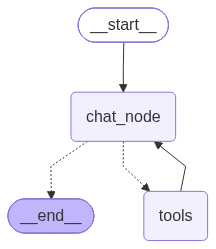

In [10]:
chatbot = graph.compile()
chatbot

In [11]:
# Regular Chat
out = chatbot.invoke({"messages": [HumanMessage(content="Hello! How are you?")]})
print(out["messages"][-1].content)

Hello! I’m doing great—thanks for asking. How can I help you today?


In [12]:
# chat requiring tool
out = chatbot.invoke({"messages" : [HumanMessage(content="What is 3291382913*321392+1271")]})
print(out["messages"][-1].content)

The result of the calculation is:

\[
3291382913 \times 321392 + 1271 = 1{,}057{,}824{,}137{,}176{,}167
\]


In [13]:
# Chat requiring tool
out = chatbot.invoke({"messages" : [HumanMessage(content="How to get a SWE job as a fresher in 2026?")]})
print(out["messages"][-1].content)

Below is a practical, step‑by‑step playbook for landing a **Software Engineer (SWE) role as a fresher in 2026**.  
It blends the latest industry trends, proven hiring practices, and a realistic timeline so you can start today and finish ready for your first job offer.

---

## 1. Know the Landscape (2026 Snapshot)

| Trend | What It Means for Freshers | Why It Matters |
|-------|---------------------------|----------------|
| **AI‑First Development** | ML/LLM integration, prompt‑engineering, data‑centric design | Companies want engineers who can build AI‑enhanced products. |
| **Serverless & Edge Computing** | Cloud functions, edge runtimes (Cloudflare Workers, AWS Lambda@Edge) | Faster, cheaper, and highly scalable deployments. |
| **Observability & SRE** | Distributed tracing, chaos engineering, automated incident response | Reliability is a core product feature. |
| **Low‑Code/No‑Code Platforms** | Rapid prototyping, citizen developers | Engineers must understand how to integrate wi

In [14]:
out = chatbot.invoke({"messages" : [HumanMessage(content="First you stock price tool to get the price of AAPL stock, then use the calculator tool to calculate 10% of that price.")]})
print(out["messages"][-1].content)

The current price of **AAPL** is **$333.63**.  
10 % of that price is **$33.36**.


In [15]:
out = chatbot.invoke({"messages" : [HumanMessage(content="Whats the weather in bhopal ?")]})
print(out["messages"][-1].content)

**Current weather in Bhopal, India**

- **Condition:** Clear sky  
- **Temperature:** 23.44 °C (feels like 23.46 °C)  
- **Humidity:** 62 %  
- **Wind speed:** 1.13 m/s  

Enjoy your day!


In [16]:
out = chatbot.invoke({"messages" : [HumanMessage(content="lATEST news in ai ?")]})
print(out["messages"][-1].content)

**Latest AI Headlines (May – July 2026)**  

| Date | Story | Key Take‑away | Source |
|------|-------|---------------|--------|
| **July 10 2026** | *Lucyd Smart Glasses get Claude AI* | Anthropic is partnering with Lucyd to embed Claude AI in smart‑glasses, turning the eyewear into a real‑time conversational assistant. | TechCrunch |
| **July 2 2026** | *New York requires AI‑generated ad disclosures* | New York City becomes the first U.S. jurisdiction to mandate that any AI‑generated advertising content be clearly labeled, aiming to curb misinformation. | TechCrunch |
| **July 2 2026** | *SoundHound AI acquires LivePerson* | SoundHound expands from voice recognition into conversational AI, targeting enterprise contact‑center, healthcare, and finance markets. | Simply Wall St |
| **May 21 2026** | *Nvidia’s memory costs surge 485 %* | The cost of building next‑gen AI systems has jumped, with Nvidia’s new GPUs now priced at roughly $7.8 million per system. | TechCrunch |
| **May 18 202